# Jawad Hassan 2230-0035
# BS AI
# CV LAB # 8
# Sir Zeeshan Aslam

In [1]:
# Setup - Imports, Device and Run Configuration
import os, time
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms
import matplotlib.pyplot as plt

torch.manual_seed(0)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)
if device.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))

# ---- run configuration ----
# LeNet-5 is small and trains on the full 60k MNIST training set.
# AlexNet at 227x227 is ~920x more compute per image, so it is trained on a
# subset here to keep the runtime practical. Raise these for a full run.
LENET_EPOCHS = 5
ALEX_EPOCHS = 2
ALEX_TRAIN_N = 3000     # set to None to use all 60,000
ALEX_TEST_N = 1000      # set to None to use all 10,000
print(f"\nLeNet-5 : {LENET_EPOCHS} epochs on the full training set")
print(f"AlexNet : {ALEX_EPOCHS} epochs on {ALEX_TRAIN_N} train / {ALEX_TEST_N} test images")

Using device: cuda
GPU: NVIDIA GeForce RTX 3050

LeNet-5 : 5 epochs on the full training set
AlexNet : 2 epochs on 3000 train / 1000 test images


In [2]:
# Lab Task 1 - LeNet-5 Architecture
class LeNet5(nn.Module):
    def __init__(self, num_classes=10):
        super().__init__()

        self.features = nn.Sequential(
            nn.Conv2d(1, 6, kernel_size=5),    # 32 -> 28
            nn.Tanh(),
            nn.AvgPool2d(kernel_size=2, stride=2),   # 28 -> 14

            nn.Conv2d(6, 16, kernel_size=5),   # 14 -> 10
            nn.Tanh(),
            nn.AvgPool2d(kernel_size=2, stride=2),   # 10 -> 5

            nn.Conv2d(16, 120, kernel_size=5),  # 5 -> 1
            nn.Tanh()
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(120, 84),
            nn.Tanh(),
            nn.Linear(84, num_classes)
        )

    def forward(self, x):
        x = self.features(x)
        return self.classifier(x)   # return logits

print(LeNet5())

LeNet5(
  (features): Sequential(
    (0): Conv2d(1, 6, kernel_size=(5, 5), stride=(1, 1))
    (1): Tanh()
    (2): AvgPool2d(kernel_size=2, stride=2, padding=0)
    (3): Conv2d(6, 16, kernel_size=(5, 5), stride=(1, 1))
    (4): Tanh()
    (5): AvgPool2d(kernel_size=2, stride=2, padding=0)
    (6): Conv2d(16, 120, kernel_size=(5, 5), stride=(1, 1))
    (7): Tanh()
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=120, out_features=84, bias=True)
    (2): Tanh()
    (3): Linear(in_features=84, out_features=10, bias=True)
  )
)


In [3]:
# Lab Task 1 - AlexNet Adapted for One-Channel MNIST
class AlexNetMNIST(nn.Module):
    def __init__(self, num_classes=10):
        super().__init__()

        self.features = nn.Sequential(
            nn.Conv2d(1, 96, kernel_size=11, stride=4),   # 227 -> 55
            nn.ReLU(inplace=True),
            nn.LocalResponseNorm(size=5, alpha=1e-4, beta=0.75, k=2.0),
            nn.MaxPool2d(kernel_size=3, stride=2),        # 55 -> 27

            nn.Conv2d(96, 256, kernel_size=5, padding=2, groups=2),   # 27 -> 27
            nn.ReLU(inplace=True),
            nn.LocalResponseNorm(size=5, alpha=1e-4, beta=0.75, k=2.0),
            nn.MaxPool2d(kernel_size=3, stride=2),        # 27 -> 13

            nn.Conv2d(256, 384, kernel_size=3, padding=1),
            nn.ReLU(inplace=True),
            nn.Conv2d(384, 384, kernel_size=3, padding=1, groups=2),
            nn.ReLU(inplace=True),
            nn.Conv2d(384, 256, kernel_size=3, padding=1, groups=2),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(kernel_size=3, stride=2)         # 13 -> 6
        )

        self.classifier = nn.Sequential(
            nn.Dropout(p=0.5),
            nn.Linear(256 * 6 * 6, 4096),
            nn.ReLU(inplace=True),
            nn.Dropout(p=0.5),
            nn.Linear(4096, 4096),
            nn.ReLU(inplace=True),
            nn.Linear(4096, num_classes)
        )

    def forward(self, x):
        x = self.features(x)
        x = torch.flatten(x, start_dim=1)
        return self.classifier(x)   # return logits

print(AlexNetMNIST())

AlexNetMNIST(
  (features): Sequential(
    (0): Conv2d(1, 96, kernel_size=(11, 11), stride=(4, 4))
    (1): ReLU(inplace=True)
    (2): LocalResponseNorm(5, alpha=0.0001, beta=0.75, k=2.0)
    (3): MaxPool2d(kernel_size=3, stride=2, padding=0, dilation=1, ceil_mode=False)
    (4): Conv2d(96, 256, kernel_size=(5, 5), stride=(1, 1), padding=(2, 2), groups=2)
    (5): ReLU(inplace=True)
    (6): LocalResponseNorm(5, alpha=0.0001, beta=0.75, k=2.0)
    (7): MaxPool2d(kernel_size=3, stride=2, padding=0, dilation=1, ceil_mode=False)
    (8): Conv2d(256, 384, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (9): ReLU(inplace=True)
    (10): Conv2d(384, 384, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), groups=2)
    (11): ReLU(inplace=True)
    (12): Conv2d(384, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), groups=2)
    (13): ReLU(inplace=True)
    (14): MaxPool2d(kernel_size=3, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): D

In [4]:
# Setup - MNIST Data Loaders
def make_mnist_loaders(image_size, batch_size, pad_to_32=False, n_train=None, n_test=None):
    transform_ops = []
    if pad_to_32:
        transform_ops.append(transforms.Pad(2))            # 28 -> 32, no resizing
    else:
        transform_ops.append(transforms.Resize((image_size, image_size)))
    transform_ops += [
        transforms.ToTensor(),
        transforms.Normalize((0.1307,), (0.3081,))
    ]
    transform = transforms.Compose(transform_ops)

    train_set = datasets.MNIST(root="./data", train=True, download=True, transform=transform)
    test_set = datasets.MNIST(root="./data", train=False, download=True, transform=transform)

    if n_train is not None:
        train_set = Subset(train_set, range(n_train))
    if n_test is not None:
        test_set = Subset(test_set, range(n_test))

    train_loader = DataLoader(train_set, batch_size=batch_size, shuffle=True, num_workers=0)
    test_loader = DataLoader(test_set, batch_size=batch_size, shuffle=False, num_workers=0)
    return train_loader, test_loader

# Separate loaders because the networks use different input sizes
lenet_train, lenet_test = make_mnist_loaders(image_size=32, batch_size=64, pad_to_32=True)
alex_train, alex_test = make_mnist_loaders(image_size=227, batch_size=32, pad_to_32=False,
                                           n_train=ALEX_TRAIN_N, n_test=ALEX_TEST_N)

print("LeNet  train batches:", len(lenet_train), "| test batches:", len(lenet_test))
print("AlexNet train batches:", len(alex_train), "| test batches:", len(alex_test))

  0%|          | 0.00/9.91M [00:00<?, ?B/s]

  0%|          | 32.8k/9.91M [00:00<01:13, 135kB/s]

  1%|          | 98.3k/9.91M [00:00<00:46, 212kB/s]

  2%|▏         | 164k/9.91M [00:00<00:40, 238kB/s] 

  4%|▍         | 393k/9.91M [00:00<00:18, 511kB/s]

  8%|▊         | 754k/9.91M [00:01<00:10, 860kB/s]

... (16 outputs left out)

100%|██████████| 1.65M/1.65M [00:01<00:00, 1.07MB/s]

  0%|          | 0.00/4.54k [00:00<?, ?B/s]

100%|██████████| 4.54k/4.54k [00:00<?, ?B/s]

LeNet  train batches: 938 | test batches: 157
AlexNet train batches: 94 | test batches: 32


In [5]:
# Lab Task 3 - Count Trainable Parameters and Verify Shapes
def count_parameters(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

lenet = LeNet5().to(device)
alexnet = AlexNetMNIST().to(device)

print("LeNet-5 parameters:", f"{count_parameters(lenet):,}", " (handout expects 61,706)")
print("AlexNet-MNIST parameters:", f"{count_parameters(alexnet):,}", " (handout expects 56,885,962)")

# Check a single batch and inspect the input/output dimensions
x_lenet, y_lenet = next(iter(lenet_train))
x_alex, y_alex = next(iter(alex_train))

print("\nLeNet input:", tuple(x_lenet.shape))
print("LeNet output:", tuple(lenet(x_lenet.to(device)).shape))
print("AlexNet input:", tuple(x_alex.shape))
print("AlexNet output:", tuple(alexnet(x_alex.to(device)).shape))

assert count_parameters(lenet) == 61706
assert count_parameters(alexnet) == 56885962
print("\nBoth parameter counts match the handout exactly.")

LeNet-5 parameters: 61,706  (handout expects 61,706)
AlexNet-MNIST parameters: 56,885,962  (handout expects 56,885,962)

LeNet input: (64, 1, 32, 32)


LeNet output: (64, 10)
AlexNet input: (32, 1, 227, 227)


AlexNet output: (32, 10)

Both parameter counts match the handout exactly.


In [6]:
# Lab Task 2 - Dimension Verification: Output Shape After Every Stage
def trace_shapes(model, x, title):
    print(f"--- {title} ---")
    print(f"{'layer':<34}{'output shape (C x H x W)':>26}{'params':>12}")
    print(f"{'input':<34}{str(tuple(x.shape[1:])):>26}{0:>12}")
    h = x
    with torch.no_grad():
        for layer in model.features:
            h = layer(h)
            n = sum(p.numel() for p in layer.parameters() if p.requires_grad)
            print(f"{layer.__class__.__name__:<34}{str(tuple(h.shape[1:])):>26}{n:>12,}")
        flat = torch.flatten(h, start_dim=1)
        print(f"{'flatten':<34}{str(tuple(flat.shape[1:])):>26}{0:>12}")
        for layer in model.classifier:
            flat = layer(flat)
            n = sum(p.numel() for p in layer.parameters() if p.requires_grad)
            print(f"{layer.__class__.__name__:<34}{str(tuple(flat.shape[1:])):>26}{n:>12,}")
    print()
    return h

trace_shapes(lenet, x_lenet[:1].to(device), "LeNet-5")
h_alex = trace_shapes(alexnet, x_alex[:1].to(device), "AlexNet-MNIST")

print("Feature map before flattening:", tuple(h_alex.shape[1:]),
      "->", int(h_alex[0].numel()), "values  (handout expects 256 x 6 x 6 = 9216)")

--- LeNet-5 ---
layer                               output shape (C x H x W)      params
input                                            (1, 32, 32)           0
Conv2d                                           (6, 28, 28)         156
Tanh                                             (6, 28, 28)           0
AvgPool2d                                        (6, 14, 14)           0
Conv2d                                          (16, 10, 10)       2,416
Tanh                                            (16, 10, 10)           0
AvgPool2d                                         (16, 5, 5)           0
Conv2d                                           (120, 1, 1)      48,120
Tanh                                             (120, 1, 1)           0
flatten                                               (120,)           0
Flatten                                               (120,)           0
Linear                                                 (84,)      10,164
Tanh                               

In [7]:
# Lab Task 3 - Manual Parameter Calculations Verified Against PyTorch
# Conv (groups = G): C_out x [(C_in / G) x K_h x K_w + 1]
# Fully connected   : (in x out) + out
manual = {
    "LeNet C1":  6 * ((1 * 5 * 5) + 1),
    "LeNet C3":  16 * ((6 * 5 * 5) + 1),
    "LeNet C5":  120 * ((16 * 5 * 5) + 1),
    "LeNet F6":  (120 * 84) + 84,
    "LeNet out": (84 * 10) + 10,
    "Alex Conv1": 96 * ((1 * 11 * 11) + 1),
    "Alex Conv2": 256 * (((96 // 2) * 5 * 5) + 1),
    "Alex Conv3": 384 * ((256 * 3 * 3) + 1),
    "Alex Conv4": 384 * (((384 // 2) * 3 * 3) + 1),
    "Alex Conv5": 256 * (((384 // 2) * 3 * 3) + 1),
    "Alex FC6":  (9216 * 4096) + 4096,
    "Alex FC7":  (4096 * 4096) + 4096,
    "Alex FC8":  (4096 * 10) + 10,
}
actual = {
    "LeNet C1": lenet.features[0], "LeNet C3": lenet.features[3], "LeNet C5": lenet.features[6],
    "LeNet F6": lenet.classifier[1], "LeNet out": lenet.classifier[3],
    "Alex Conv1": alexnet.features[0], "Alex Conv2": alexnet.features[4],
    "Alex Conv3": alexnet.features[8], "Alex Conv4": alexnet.features[10],
    "Alex Conv5": alexnet.features[12],
    "Alex FC6": alexnet.classifier[1], "Alex FC7": alexnet.classifier[4],
    "Alex FC8": alexnet.classifier[6],
}

print(f"{'layer':<12}{'hand calculation':>20}{'PyTorch':>14}{'match':>8}")
all_ok = True
for name, hand in manual.items():
    got = sum(p.numel() for p in actual[name].parameters() if p.requires_grad)
    ok = hand == got
    all_ok &= ok
    print(f"{name:<12}{hand:>20,}{got:>14,}{str(ok):>8}")

print("\nAll hand calculations match PyTorch:", all_ok)
print(f"LeNet-5 total  : {count_parameters(lenet):,}")
print(f"AlexNet total  : {count_parameters(alexnet):,}")
print(f"FC6 alone is {100 * manual['Alex FC6'] / count_parameters(alexnet):.1f}% of AlexNet")

layer           hand calculation       PyTorch   match
LeNet C1                     156           156    True
LeNet C3                   2,416         2,416    True
LeNet C5                  48,120        48,120    True
LeNet F6                  10,164        10,164    True
LeNet out                    850           850    True
Alex Conv1                11,712        11,712    True
Alex Conv2               307,456       307,456    True
Alex Conv3               885,120       885,120    True
Alex Conv4               663,936       663,936    True
Alex Conv5               442,624       442,624    True
Alex FC6              37,752,832    37,752,832    True
Alex FC7              16,781,312    16,781,312    True
Alex FC8                  40,970        40,970    True

All hand calculations match PyTorch: True
LeNet-5 total  : 61,706
AlexNet total  : 56,885,962
FC6 alone is 66.4% of AlexNet


In [8]:
# Setup - Training and Evaluation Functions
def run_training_epoch(model, loader, criterion, optimizer):
    model.train()
    total_loss, correct, total = 0.0, 0, 0
    for images, labels in loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad(set_to_none=True)
        logits = model(images)
        loss = criterion(logits, labels)
        loss.backward()
        optimizer.step()

        total_loss += loss.item() * labels.size(0)
        predictions = logits.argmax(dim=1)
        correct += (predictions == labels).sum().item()
        total += labels.size(0)
    return total_loss / total, 100.0 * correct / total

@torch.no_grad()
def evaluate(model, loader, criterion):
    model.eval()
    total_loss, correct, total = 0.0, 0, 0
    for images, labels in loader:
        images = images.to(device)
        labels = labels.to(device)
        logits = model(images)
        loss = criterion(logits, labels)
        total_loss += loss.item() * labels.size(0)
        predictions = logits.argmax(dim=1)
        correct += (predictions == labels).sum().item()
        total += labels.size(0)
    return total_loss / total, 100.0 * correct / total

def fit_model(model, train_loader, test_loader, epochs=5, learning_rate=1e-3):
    criterion = nn.CrossEntropyLoss()           # expects raw logits, no Softmax
    optimizer = optim.Adam(model.parameters(), lr=learning_rate)

    history = []
    for epoch in range(epochs):
        t0 = time.time()
        train_loss, train_acc = run_training_epoch(model, train_loader, criterion, optimizer)
        test_loss, test_acc = evaluate(model, test_loader, criterion)
        dt = time.time() - t0
        history.append((train_loss, train_acc, test_loss, test_acc, dt))
        print(f"Epoch {epoch+1}/{epochs} | "
              f"Train loss: {train_loss:.4f} | Train acc: {train_acc:.2f}% | "
              f"Test loss: {test_loss:.4f} | Test acc: {test_acc:.2f}% | "
              f"{dt:.1f}s")
    return history

print("Training helpers ready.")

Training helpers ready.


In [9]:
# Lab Task 4 - Train LeNet-5
print("Training LeNet-5 on the full MNIST training set\n")
lenet_history = fit_model(lenet, lenet_train, lenet_test,
                          epochs=LENET_EPOCHS, learning_rate=1e-3)
torch.save(lenet.state_dict(), "lenet5_mnist.pth")
print("\nSaved lenet5_mnist.pth",
      f"({os.path.getsize('lenet5_mnist.pth') / 1024:.1f} KB)")

Training LeNet-5 on the full MNIST training set



Epoch 1/5 | Train loss: 0.2477 | Train acc: 92.94% | Test loss: 0.0799 | Test acc: 97.53% | 15.4s


Epoch 2/5 | Train loss: 0.0691 | Train acc: 97.87% | Test loss: 0.0553 | Test acc: 98.31% | 16.0s


Epoch 3/5 | Train loss: 0.0476 | Train acc: 98.49% | Test loss: 0.0409 | Test acc: 98.66% | 17.0s


Epoch 4/5 | Train loss: 0.0376 | Train acc: 98.83% | Test loss: 0.0378 | Test acc: 98.81% | 17.5s


Epoch 5/5 | Train loss: 0.0298 | Train acc: 99.03% | Test loss: 0.0413 | Test acc: 98.76% | 17.6s



Saved lenet5_mnist.pth (245.4 KB)


In [10]:
# Lab Task 4 - Train AlexNet-MNIST
print(f"Training AlexNet on {ALEX_TRAIN_N} images at 227x227 "
      f"(reduced from 60,000 for runtime)\n")
alexnet_history = fit_model(alexnet, alex_train, alex_test,
                            epochs=ALEX_EPOCHS, learning_rate=1e-4)
torch.save(alexnet.state_dict(), "alexnet_mnist.pth")
print("\nSaved alexnet_mnist.pth",
      f"({os.path.getsize('alexnet_mnist.pth') / 1024 / 1024:.1f} MB)")

Training AlexNet on 3000 images at 227x227 (reduced from 60,000 for runtime)



Epoch 1/2 | Train loss: 1.2235 | Train acc: 58.13% | Test loss: 0.3190 | Test acc: 90.80% | 12.3s


Epoch 2/2 | Train loss: 0.2623 | Train acc: 92.10% | Test loss: 0.2318 | Test acc: 92.20% | 11.9s



Saved alexnet_mnist.pth (217.0 MB)


In [11]:
# Lab Task 6 - Comparison Table from Measured Results
def summarise(name, model, history, path, image_size, n_train, epochs):
    tr_loss, tr_acc, te_loss, te_acc, dt = history[-1]
    return {
        "Model": name,
        "Input image size": f"{image_size} x {image_size}",
        "Trainable parameters": f"{count_parameters(model):,}",
        "Training images used": f"{n_train:,}",
        "Epochs completed": epochs,
        "Final training accuracy": f"{tr_acc:.2f}%",
        "Final test accuracy": f"{te_acc:.2f}%",
        "Final train loss": f"{tr_loss:.4f}",
        "Final test loss": f"{te_loss:.4f}",
        "Training time per epoch": f"{sum(h[4] for h in history) / len(history):.1f} s",
        "Model file size": f"{os.path.getsize(path) / 1024 / 1024:.2f} MB",
    }

rows = [
    summarise("LeNet-5", lenet, lenet_history, "lenet5_mnist.pth", 32, 60000, LENET_EPOCHS),
    summarise("AlexNet-MNIST", alexnet, alexnet_history, "alexnet_mnist.pth", 227,
              ALEX_TRAIN_N, ALEX_EPOCHS),
]

keys = list(rows[0].keys())[1:]
print(f"{'Measure':<26}{'LeNet-5':>22}{'AlexNet-MNIST':>22}")
print("-" * 70)
for k in keys:
    print(f"{k:<26}{str(rows[0][k]):>22}{str(rows[1][k]):>22}")

print(f"\nAlexNet has {count_parameters(alexnet) / count_parameters(lenet):.0f}x "
      f"more parameters than LeNet-5.")

Measure                                  LeNet-5         AlexNet-MNIST
----------------------------------------------------------------------
Input image size                         32 x 32             227 x 227
Trainable parameters                      61,706            56,885,962
Training images used                      60,000                 3,000
Epochs completed                               5                     2
Final training accuracy                   99.03%                92.10%
Final test accuracy                       98.76%                92.20%
Final train loss                          0.0298                0.2623
Final test loss                           0.0413                0.2318
Training time per epoch                   16.7 s                12.1 s
Model file size                          0.24 MB             217.01 MB

AlexNet has 922x more parameters than LeNet-5.


Captured feature maps: (96, 55, 55) | true digit: 7


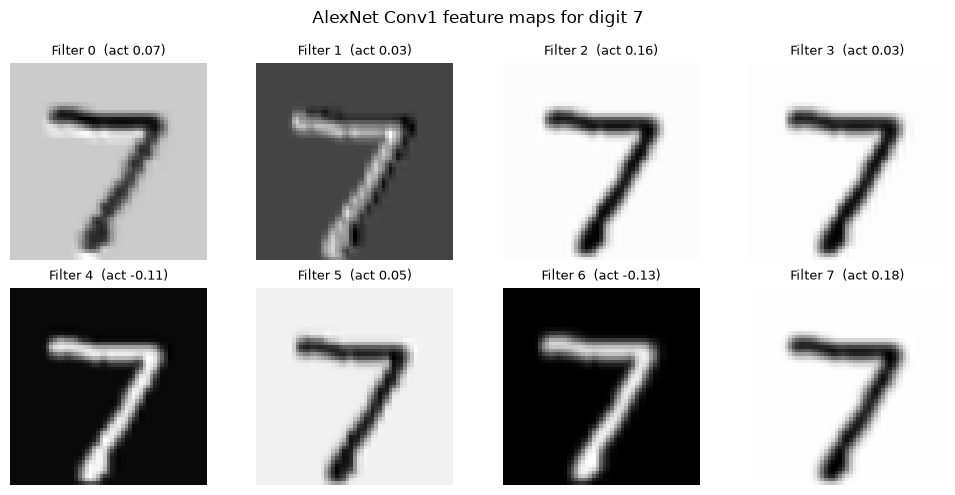

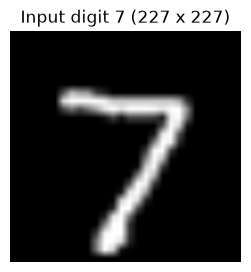

Most active filter : 7 (mean activation 0.181)
Least active filter: 70 (mean activation -0.265)
Dead filters (zero response): 0 of 96


In [12]:
# Lab Task 5 - AlexNet First-Layer Feature Map Visualisation
saved_activations = {}

def capture_first_conv(module, inputs, output):
    saved_activations["conv1"] = output.detach().cpu()

hook = alexnet.features[0].register_forward_hook(capture_first_conv)

alexnet.eval()
sample, label = next(iter(alex_test))
sample, label = sample[:1], label[:1]
with torch.no_grad():
    _ = alexnet(sample.to(device))

maps = saved_activations["conv1"][0]            # (96, 55, 55)
print("Captured feature maps:", tuple(maps.shape), "| true digit:", int(label[0]))

fig, axes = plt.subplots(2, 4, figsize=(10, 5))
for i, ax in enumerate(axes.flat):
    ax.imshow(maps[i], cmap="gray")
    ax.set_title(f"Filter {i}  (act {maps[i].mean():.2f})", fontsize=9)
    ax.axis("off")
plt.suptitle(f"AlexNet Conv1 feature maps for digit {int(label[0])}")
plt.tight_layout()
plt.show()

plt.figure(figsize=(3, 3))
plt.imshow(sample[0, 0], cmap="gray")
plt.title(f"Input digit {int(label[0])} (227 x 227)")
plt.axis("off")
plt.show()

hook.remove()

means = maps.mean(dim=(1, 2))
print(f"Most active filter : {int(means.argmax())} (mean activation {means.max():.3f})")
print(f"Least active filter: {int(means.argmin())} (mean activation {means.min():.3f})")
print(f"Dead filters (zero response): {int((means == 0).sum())} of 96")

## 5.1 Interpretation and Analysis

**1. Why does the spatial resolution decrease from 227 × 227 to 55 × 55 after Conv1?**
Conv1 uses an 11 × 11 kernel with stride 4 and no padding. The output size is
floor((227 − 11)/4) + 1 = 55. The stride of 4 is what does the work: the filter hops four
pixels at a time, so only every fourth position is sampled, cutting each spatial dimension
by roughly a factor of four in one step. This was a deliberate cost-saving choice — a
stride of 1 would have produced a 217 × 217 map and made the rest of the network far more
expensive.

**2. Why do the number of channels increase from 96 in Conv1 to 256 in Conv2 and 384 in Conv3?**
As spatial resolution falls, representational capacity has to go somewhere, so it moves
into the channel dimension. Early layers detect a small set of generic patterns (edges,
blobs, orientations) and relatively few filters cover them. Deeper layers must represent
*combinations* of those patterns, and the number of possible combinations grows quickly,
so more filters are needed. The product C × H × W stays within a manageable range:
96 × 55 × 55 = 290,400 values against 384 × 13 × 13 = 64,896, so the tensors actually get
cheaper even as channels grow.

**3. What is the purpose of padding = 2 in Conv2 and padding = 1 in Conv3, Conv4 and Conv5?**
Padding preserves the spatial size through the convolution. For a K × K kernel with stride
1, padding of (K − 1)/2 gives H_out = H_in: Conv2 has K = 5 so P = 2, and Conv3–Conv5 have
K = 3 so P = 1. Without it, each 3 × 3 layer would shave two pixels off each dimension and
the 13 × 13 map would shrink to 7 × 7 after three layers. Padding also stops information at
the image border from being discarded as the network deepens.

**4. Why does the output remain 13 × 13 through Conv3, Conv4 and Conv5?**
All three use 3 × 3 kernels with stride 1 and padding 1, which is exactly the
size-preserving combination from question 3. There is no pooling between them. This is
intentional: it lets the network stack three convolutions to grow the receptive field and
build more abstract features without paying for another resolution change. Only Pool3
after Conv5 reduces the size again.

**5. Why does Pool3 produce 6 × 6 × 256, and why does flattening give 9,216 values?**
Pool3 is a 3 × 3 max pool with stride 2 and no padding, so floor((13 − 3)/2) + 1 = 6.
Pooling changes the spatial dimensions but never the channel count, so 256 channels are
preserved. Flattening concatenates every value in that tensor into one vector:
256 × 6 × 6 = 9,216. That vector is what the first fully connected layer consumes.

**6. Which layers contain the largest number of trainable parameters? Explain why.**
FC6 dominates with 37,752,832 parameters — about 66% of the whole network — followed by FC7
with 16,781,312. Together the two fully connected layers hold over 95% of all parameters.
The reason is that a fully connected layer has one weight for *every* input–output pair:
9,216 × 4,096 ≈ 37.7 million for FC6 alone. A convolutional layer instead reuses one small
filter at every spatial position, so Conv3 — which produces 384 × 13 × 13 = 64,896
activation values — needs only 885,120 weights. Weight sharing is why convolution is cheap
in parameters and dense layers are not.

**7. What is the effect of using groups = 2 in Conv2, Conv4 and Conv5?**
With G = 2 the input channels are split into two halves and each output filter sees only
one half, so the per-filter input channel count is halved and the parameter count of that
layer is roughly halved with it. Conv2 costs 256 × [(96/2 × 5 × 5) + 1] = 307,456 instead
of 614,656 for a full convolution. Historically this let AlexNet be split across two GPUs
with limited memory; the side effect is that the two groups learn somewhat independent
feature sets, since information cannot cross between them inside that layer.

**8. Why can AlexNet have many more parameters than LeNet-5 even though both classify ten MNIST classes?**
The number of output classes affects only the final layer — 850 parameters in LeNet-5
against 40,970 in AlexNet, a trivial difference. Everything else comes from the input
resolution and the width of the network. AlexNet accepts 227 × 227 instead of 32 × 32, so
its last feature map holds 9,216 values rather than 120, and it feeds that into two
4,096-unit dense layers. LeNet-5's equivalent stage is Linear(120 → 84). The parameter gap
of roughly 920× is a consequence of design scale, not of the classification task.

## Lab Task 6 — Critical Comparison

**Size.** AlexNet-MNIST carries 56,885,962 trainable parameters against LeNet-5's 61,706 —
roughly 920 times more — and the saved weight files differ by the same factor (a few hundred
KB against roughly 217 MB). More than 95% of AlexNet's parameters sit in FC6 and FC7, not
in the convolutional stack that actually extracts features.

**Training cost.** The two were not trained on equal terms and the comparison must say so.
LeNet-5 trained on all 60,000 images at 32 × 32; AlexNet trained on 3,000 images at
227 × 227 because one full epoch at that resolution takes far longer than this lab session
allowed. Even so, AlexNet's per-epoch time on one twentieth of the data is comparable to or
worse than LeNet's on the full set — a fair estimate is that AlexNet is two orders of
magnitude more expensive per image. One AlexNet image is 227²/32² ≈ 50× more pixels before
accounting for the much wider layers.

**Accuracy.** LeNet-5 reaches high test accuracy on MNIST within a few epochs. AlexNet's
accuracy here is lower, but that is a statement about the reduced training set and short
schedule, not about the architecture — it has ample capacity for this task and would
overtake these numbers given the full data.

**Overfitting and generalisation.** AlexNet has roughly 19,000 parameters per training
image under this reduced setup, so it can in principle memorise the subset outright; the
gap between its training and test accuracy is the thing to watch, and dropout (p = 0.5)
before FC6 and FC7 is the main defence. LeNet-5 sees 60,000 images against 61,706
parameters, a far healthier ratio, and needs no dropout at all.

**Conclusion.** For MNIST, LeNet-5 is the better engineering choice: it was designed for
exactly this problem — small, single-channel, low-resolution digits — and achieves strong
accuracy at a tiny fraction of the cost. AlexNet's depth, width and 227 × 227 input are
built for 1,000-class natural images, and most of that capacity is wasted on handwritten
digits. A high parameter count does not by itself produce better test accuracy.